In [2]:
%load_ext autoreload
%autoreload 2

In [3]:
import sys
sys.path.append("../src")

In [4]:
import networkx as nx
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import string
import os
import json
from plotters import plot_differentiation_tree, plot_simulated_lineage_tree
from simulator import simulate_multitype_bd_with_diff, save_tree, filter_extant_lineages

## Single State

In [4]:
diff_T = nx.DiGraph()

diff_T.add_node("A", diff_time=None)

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


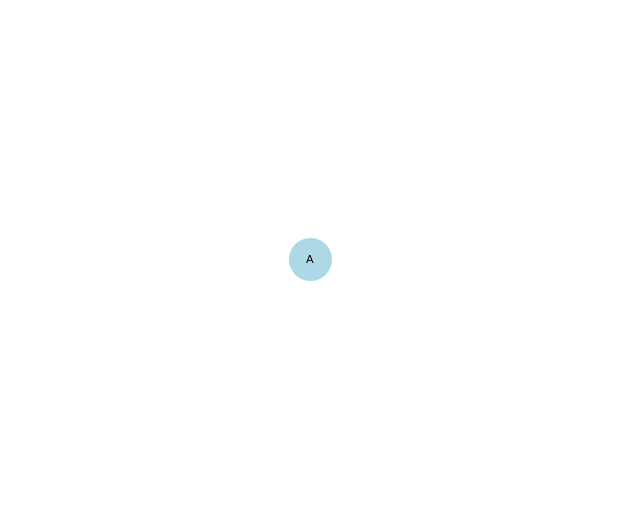

In [5]:
plot_differentiation_tree(diff_T)

KeyboardInterrupt: 

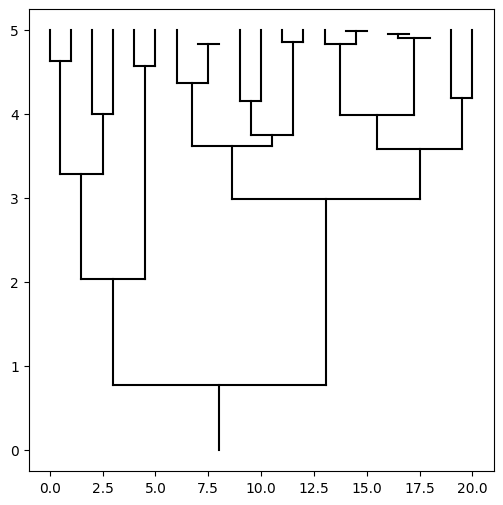

In [6]:
rooot = "../data/simulation/single"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.1, 1) for x in range(1, 21)]

for lam in lams:

    root_dir = f"{rooot}/{param_id}"

    os.makedirs(root_dir, exist_ok=True)

    lam = {
        "A": lam,
    }

    mu = {
        "A": 0,
    }

    save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

    params = {
        "birth_rates": lam,
        "death_rates": mu,
    }

    with open(f"{root_dir}/params.json", "w") as f:
        json.dump(params, f, indent=4)

    for seed in range(32):

        types = list(diff_T.nodes)

        Qs = pd.DataFrame(0.0, index=types, columns=types)

        save_dir = f"{root_dir}/{seed}"
        os.makedirs(save_dir, exist_ok=True)


        G, root = simulate_multitype_bd_with_diff(
            lam=lam,
            mu=mu,
            diff_T=diff_T,
            Qs=Qs,
            time_length=5,
            root_type="A",
            seed=seed,
        )

        # for u, v, data in G.edges(data=True):
        #     print((u, v), data)

        save_tree(G, root, f"{save_dir}/T.json")
        plot_simulated_lineage_tree(G, root)
        plt.savefig(f"{save_dir}/T.png")
        plt.close()

        G_extant = filter_extant_lineages(G, root)

        save_tree(G_extant, root, f"{save_dir}/T_extant.json")

        plot_simulated_lineage_tree(G_extant, root)
        plt.savefig(f"{save_dir}/T_extant.png")
        plt.close()

    param_id += 1


## Linear Differentiation

### differentiation map

/Users/samin/workspace/phylodynamic-carta/notebooks/../src/plotters.py:206: UserWarning: This figure includes Axes that are not compatible with tight_layout, so results might be incorrect.
  plt.tight_layout()


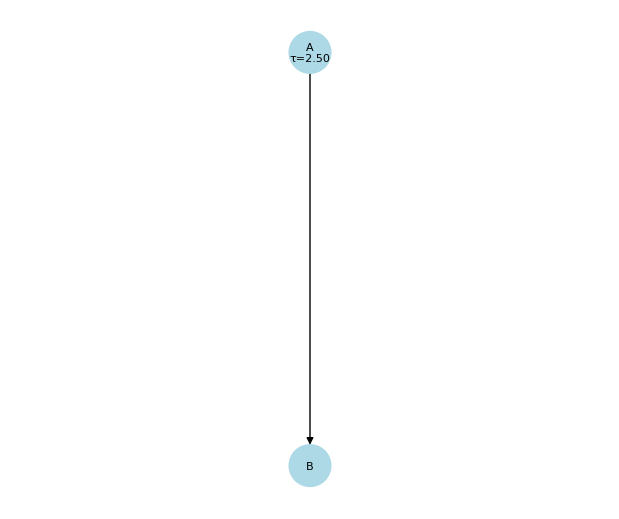

In [34]:
import string

diff_map_edges = [
    ("A", "B"),
]

diff_times = [2.5, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

### simulate tree

In [8]:
rooot = "../data/simulation/linear"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.2, 1) for x in range(1, 11)]
diff_times = [round(x * 1.0, 1) for x in range(1, 5)]

for diff_time in diff_times:
    
    diff_map_edges = [
        ("A", "B"),
    ]

    diff_times = [diff_time, None]

    diff_T = nx.DiGraph()

    for i, t in enumerate(diff_times):
        diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

    for s, e in diff_map_edges:
        diff_T.add_edge(s, e)

    for lam1 in lams:
        for lam2 in lams:

            root_dir = f"{rooot}/{param_id}"

            os.makedirs(root_dir, exist_ok=True)

            lam = {
                "A": lam1,
                "B": lam2,
            }

            mu = {
                "A": 0,
                "B": 0,
            }

            save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

            params = {
                "birth_rates": lam,
                "death_rates": mu,
            }

            with open(f"{root_dir}/params.json", "w") as f:
                json.dump(params, f, indent=4)

            # for seed in range(32):

            #     types = list(diff_T.nodes)

            #     Qs = pd.DataFrame(0.0, index=types, columns=types)

            #     save_dir = f"{root_dir}/{seed}"
            #     os.makedirs(save_dir, exist_ok=True)


            #     G, root = simulate_multitype_bd_with_diff(
            #         lam=lam,
            #         mu=mu,
            #         diff_T=diff_T,
            #         Qs=Qs,
            #         time_length=5,
            #         root_type="A",
            #         seed=seed,
            #     )

            #     # for u, v, data in G.edges(data=True):
            #     #     print((u, v), data)

            #     save_tree(G, root, f"{save_dir}/T.json")
            #     plot_simulated_lineage_tree(G, root)
            #     plt.savefig(f"{save_dir}/T.png")
            #     plt.close()

            #     G_extant = filter_extant_lineages(G, root)

            #     save_tree(G_extant, root, f"{save_dir}/T_extant.json")

            #     plot_simulated_lineage_tree(G_extant, root)
            #     plt.savefig(f"{save_dir}/T_extant.png")
            #     plt.close()

            param_id += 1


## Tree Differentiation

In [6]:
import string

diff_map_edges = [
    ("A", "B"),
    ("A", "C"),
]

diff_times = [0.5, None, None]

diff_T = nx.DiGraph()

for i, t in enumerate(diff_times):
    diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

plot_differentiation_tree(diff_T)

ImportError: requires pygraphviz http://pygraphviz.github.io/

<Figure size 600x500 with 0 Axes>

In [9]:
rooot = "../data/simulation/tree"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.4, 1) for x in range(1, 5)]
diff_times = [1.0, 2.5, 4.0]
diff_bias = [0.3, 0.5, 0.7]

for diff_time in diff_times:
        
    diff_map_edges = [
        ("A", "B"),
        ("A", "C"),
    ]

    diff_times = [diff_time, None, None]

    diff_T = nx.DiGraph()

    for i, t in enumerate(diff_times):
        diff_T.add_node(string.ascii_uppercase[i], diff_time = t)

    for s, e in diff_map_edges:
        diff_T.add_edge(s, e)

    for diff_b in diff_bias:
        types = sorted(list(diff_T.nodes()))
        Qs = pd.DataFrame(0.0, index=types, columns=types)
        Qs.loc["A", "B"] = diff_b
        Qs.loc["A", "C"] = 1 - diff_b

        for lam1 in lams:
            for lam2 in lams:
                for lam3 in lams:

                    root_dir = f"{rooot}/{param_id}"

                    os.makedirs(root_dir, exist_ok=True)

                    lam = {
                        "A": lam1,
                        "B": lam2,
                        "C": lam3,
                    }

                    mu = {
                        "A": 0,
                        "B": 0,
                        "C": 0,
                    }

                    save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

                    params = {
                        "birth_rates": lam,
                        "death_rates": mu,
                    }

                    with open(f"{root_dir}/params.json", "w") as f:
                        json.dump(params, f, indent=4)
                    
                    Qs.to_csv(f"{root_dir}/Q.csv")

                    param_id += 1


## More general graph

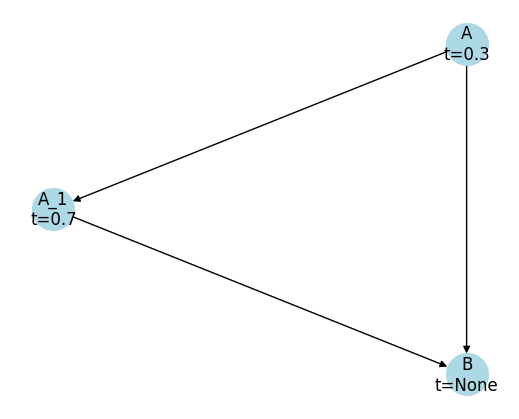

In [5]:
import string

diff_map_edges = [
    ("A", "A_1"),
    ("A", "B"),
    ("A_1", "B")
]

diff_T = nx.DiGraph()

for s, e in diff_map_edges:
    diff_T.add_edge(s, e)

diff_T.nodes['A']['diff_time'] = 0.3
diff_T.nodes['A_1']['diff_time'] = 0.7
diff_T.nodes['B']['diff_time'] = None

plot_differentiation_tree(diff_T)

In [8]:
rooot = "../data/simulation/2_stage"
os.makedirs(rooot, exist_ok=True)

param_id = 0

lams = [round(x * 0.3, 1) for x in range(1, 7)]
diff_times_1 = [1.0, 2.5, 4.0]
diff_times_2 = [2.0, 4.5]
diff_bias = [0.3, 0.5, 0.7]

for diff_time_1 in diff_times_1:

    for diff_time_2 in diff_times_2:

        if diff_time_1 >= diff_time_2: continue
        
        diff_map_edges = [
            ("A", "A_1"),
            ("A", "B"),
            ("A_1", "B")
        ]

        diff_T = nx.DiGraph()

        for s, e in diff_map_edges:
            diff_T.add_edge(s, e)

        diff_T.nodes['A']['diff_time'] = diff_time_1
        diff_T.nodes['A_1']['diff_time'] = diff_time_2
        diff_T.nodes['B']['diff_time'] = None

        for diff_b in diff_bias:
            types = sorted(list(diff_T.nodes()))
            Qs = pd.DataFrame(0.0, index=types, columns=types)
            Qs.loc["A", "A_1"] = diff_b
            Qs.loc["A", "B"] = 1 - diff_b
            Qs.loc["A_1", "B"] = 1

            for lam1 in lams:
                for lam2 in lams:
            
                    root_dir = f"{rooot}/{param_id}"

                    os.makedirs(root_dir, exist_ok=True)

                    lam = {
                        "A": lam1,
                        "A_1": lam1,
                        "B": lam2,
                    }

                    mu = {
                        "A": 0,
                        "A_1": 0,
                        "B": 0,
                    }

                    save_tree(diff_T, "A", f"{root_dir}/diff_T.json")

                    params = {
                        "birth_rates": lam,
                        "death_rates": mu,
                    }

                    with open(f"{root_dir}/params.json", "w") as f:
                        json.dump(params, f, indent=4)
                    
                    Qs.to_csv(f"{root_dir}/Q.csv")

                    param_id += 1

print(param_id)

432
